```markdown
# Aula Prática: Regressão Linear com StatsModels 🚗📈

Bem-vindo à nossa aula prática sobre **Regressão Linear**! Neste notebook, vamos investigar o famoso conjunto de dados `mtcars` para entender quais fatores influenciam o consumo de combustível dos carros (medido em milhas por galão, ou **mpg**).

Você aprenderá a importar dados, analisar correlações graficamente, construir e treinar modelos lineares usando a biblioteca `statsmodels`, e validar as premissas estatísticas necessárias para garantir que o seu modelo é confiável através da análise de resíduos.

---

## 🎯 Objetivos de Aprendizagem
Ao final deste notebook, você será capaz de:
1. **Identificar relações lineares** entre variáveis contínuas usando matrizes de correlação e gráficos de dispersão.
2. **Construir e interpretar um modelo de Regressão Linear Múltipla** utilizando a sintaxe de fórmulas do `statsmodels`.
3. **Avaliar a qualidade do modelo** através de métricas fundamentais como $R^2$, AIC e BIC.
4. **Analisar a distribuição dos resíduos** graficamente (histograma e Q-Q Plot) e estatisticamente (teste de Shapiro-Wilk) para validar as hipóteses do modelo.

---

## 🛠️ Bibliotecas Utilizadas e Pré-requisitos

Para esta aula, usaremos o ecossistema padrão de análise de dados em Python:
*   **`pandas` (pd):** Essencial para carregar, limpar e manipular tabelas de dados (DataFrames).
*   **`numpy` (np):** Biblioteca para computação matemática e manipulação de arrays.
*   **`matplotlib.pyplot` (plt):** Ferramenta fundamental para a construção de gráficos e visualizações customizadas.
*   **`seaborn` (sns):** Construída sobre o Matplotlib, facilita a criação de gráficos estatísticos atraentes e complexos (como mapas de calor e dispersões) com poucas linhas de código.
*   **`statsmodels.formula.api` (sm):** Biblioteca focada em modelos estatísticos. Usaremos a API de fórmulas, que nos permite definir modelos lineares de forma intuitiva (semelhante à linguagem R).
*   **`scipy.stats` (stats):** Ferramenta científica que utilizaremos especificamente para testes de hipóteses estatísticas e validação de distribuições.
```

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import scipy.stats as stats
import seaborn as sns

```markdown
### Passo 1: Carregamento do Dataset

**O que este passo faz:** Carrega os dados do arquivo CSV chamado `mt_cars.csv` para dentro de um DataFrame do Pandas chamado `base`, mostrando as primeiras linhas logo em seguida.

**Por que é necessário:** Antes de qualquer análise matemática ou construção de modelo, precisamos trazer os dados brutos para o ambiente Python e inspecionar visualmente sua estrutura (colunas, tipos de dados e os primeiros registros).

*   `Unnamed: 0`: Representa o nome/modelo do carro (ex: Mazda RX4).
*   `mpg` (*miles per gallon*): Nossa variável alvo (consumo de combustível).
*   `cyl`: Quantidade de cilindros.
*   `disp`: Deslocamento do motor (cilindrada).
*   `hp` (*horsepower*): Potência do motor.
*   `drat`: Relação do eixo traseiro.
*   `wt` (*weight*): Peso do carro.
*   `qsec`: Tempo que o carro leva para percorrer 1/4 de milha.
*   `vs`: Tipo de motor (0 = em V, 1 = em linha).
*   `am`: Tipo de transmissão (0 = automática, 1 = manual).
*   `gear`: Número de marchas.
*   `carb`: Número de carburadores.
```

In [ ]:
base = pd.read_csv('mt_cars.csv')

,Unnamed: 0,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


```markdown
### Passo 2: Visualizando os dados com `.head()`

**O que este passo faz:** Exibe de forma mais limpa e estruturada as 5 primeiras linhas do DataFrame.

**Por que é necessário:** Permite verificar se o carregamento foi feito com sucesso e se os alinhamentos das colunas estão corretos antes de realizarmos qualquer alteração.
```

In [ ]:
base.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


```markdown
### Passo 3: Limpeza de Dados (Remoção de Coluna Irrelevante)

**O que este passo faz:** Remove a coluna `Unnamed: 0` (que continha os nomes dos veículos) do nosso DataFrame.

**Por que é necessário:** A regressão linear e as correlações matemáticas funcionam apenas com dados numéricos contínuos ou categóricos codificados. Como a coluna `Unnamed: 0` contém textos descritivos (strings com o nome de cada veículo), ela não pode ser usada diretamente na nossa matriz de correlação ou fórmula matemática.

💡 **Para pensar:** Em vez de descartar completamente o nome dos carros, poderíamos tê-los definido como o índice (*index*) do DataFrame (`base.set_index('Unnamed: 0')`). Isso preservaria a informação visual sem atrapalhar os cálculos estatísticos.
```

In [ ]:
base = base.drop(['Unnamed: 0'], axis=1)

```markdown
### Passo 4: Análise de Correlação Linear

**O que este passo faz:** Calcula o coeficiente de correlação de Pearson entre todas as variáveis numéricas do dataset e exibe o resultado usando um Mapa de Calor (Heatmap).

**Por que ele é necessário:** A correlação mede a força e a direção da relação linear entre duas variáveis (variando de -1 a 1).
*   Valores próximos de **1** indicam forte relação positiva (quando uma variável cresce, a outra também cresce).
*   Valores próximos de **-1** indicam forte relação negativa (quando uma cresce, a outra diminui).
*   Valores próximos de **0** indicam ausência de relação linear.

Isso nos ajuda a escolher quais variáveis preditoras têm maior potencial para explicar a nossa variável alvo (`mpg`).

**Como interpretar o resultado:**
Olhando para a linha ou coluna da variável `mpg`:
*   Ela tem forte correlação negativa com `wt` (-0.87), `cyl` (-0.85) e `disp` (-0.85). Carros mais pesados e com mais cilindros consomem mais combustível (menor mpg).
*   Ela tem correlação positiva moderada com `drat` (0.68) e `am` (0.60).
```

<Axes: >

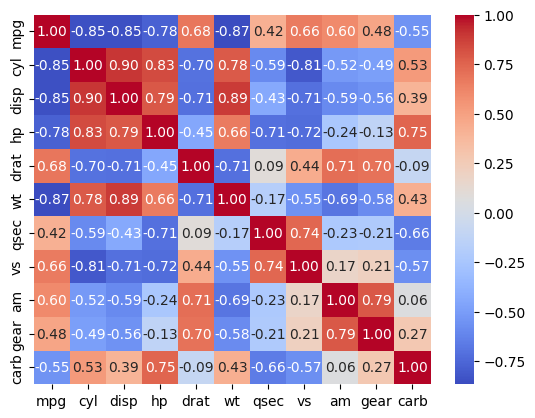

In [ ]:
corr = base.corr()
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f')

```markdown
### Passo 5: Gráficos de Dispersão (Scatter Plots)

**O que este passo faz:** Tenta plotar gráficos de dispersão individuais para as duplas de variáveis definidas na lista `column_pairs`.

**Por que ele é necessário:** O gráfico de dispersão nos permite confirmar visualmente se a relação sugerida pela correlação numérica é realmente linear ou se existem padrões não lineares ou *outliers* (valores discrepantes).

💡 **Para pensar:** Há um pequeno erro de lógica na célula de código abaixo. O loop `for` define a tupla `pair` mas tenta acessar variáveis `x_col` e `y_col` que não foram desempacotadas corretamente na linha ativa do loop. Por isso, todos os subplots acabaram repetindo o gráfico de `mpg vs cyl` (que ficou salvo na memória da última iteração ou de testes anteriores). O código correto para o loop deveria usar a linha comentada abaixo dela: `for i, (x_col, y_col) in enumerate(column_pairs):`.
```

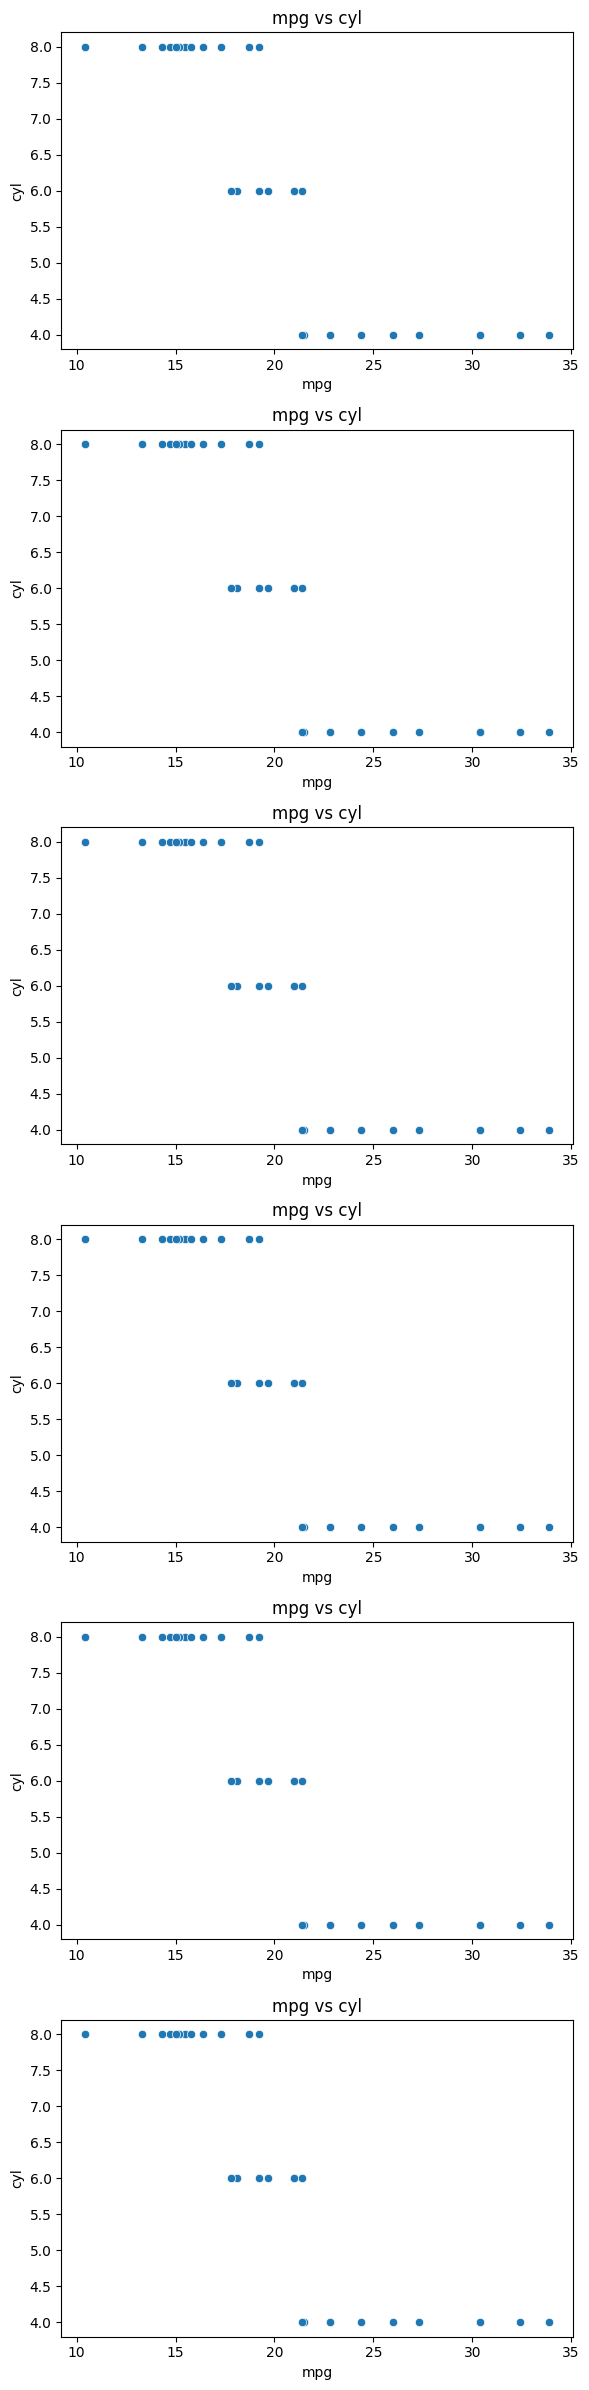

In [ ]:
column_pairs = [('mpg', 'disp'), ('mpg', 'hp'), ('mpg', 'drat'), ('mpg', 'wt'), ('mpg', 'vs'), ('mpg', 'cyl')]
n_plots = len(column_pairs)
fig, axes = plt.subplots(nrows=n_plots, figsize=(6,4 *n_plots))

for i, pair in enumerate(column_pairs):
#for i, (x_col, y_col) in enumerate(column_pairs):
    sns.scatterplot(x=x_col, y=y_col, data=base, ax=axes[i])
    #sns.regplot(x=x_col, y=y_col, data=base, ax=axes[i])
    axes[i].set_title(f'{x_col} vs {y_col}')

plt.tight_layout()
plt.show()

```markdown
### Passo 6: Criação e Ajuste do Modelo de Regressão Linear

**O que este passo faz:** Define e ajusta um modelo de regressão linear simples/múltipla usando a biblioteca `statsmodels` com a sintaxe de fórmula: `Variavel_Dependente ~ Variavel_Independente1 + Variavel_Independente2`.

**Por que ele é necessário:** É aqui que a mágica matemática acontece. O algoritmo encontra a reta (ou hiperplano) que minimiza a distância entre os pontos reais dos dados e as previsões do modelo (método dos Mínimos Quadrados Ordinários - OLS).

No código, o modelo escolhido utiliza as variáveis preditoras `drat` (relação do eixo traseiro) e `cyl` (cilindros) para prever `mpg`.

**Como interpretar os resultados da tabela OLS:**
*   **R-squared (R² = 0.740):** O coeficiente de determinação. Significa que aproximadamente 74% da variação no consumo (`mpg`) é explicada pelas variáveis `drat` e `cyl` juntas.
*   **P>|t| (p-value dos coeficientes):** Teste de hipótese para avaliar se cada variável é estatisticamente significante.
    *   Para `cyl`, o p-value é **0.000** (menor que 0.05), indicando que a quantidade de cilindros é altamente significativa para prever o consumo.
    *   Para `drat`, o p-value é **0.220** (maior que 0.05), indicando que, na presença da variável `cyl`, a variável `drat` **não** é estatisticamente significante para explicar a variação de `mpg`.
*   **AIC (167.6) e BIC (172.0):** Critérios de informação. Quanto menores estes valores, melhor e mais equilibrado (evitando sobreajuste) é o modelo.
```

In [ ]:
# aic 156.6 bic 162.5
# modelo = sm.ols(formula='mpg ~ disp + hp + wt', data=base)
# aic 165 bic 169 - não é muito bom
# modelo = sm.ols(formula='mpg ~ disp + cyl', data=base)

modelo = sm.ols(formula='mpg ~ drat + cyl', data=base)
modelo = modelo.fit()
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     41.32
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.24e-09
Time:                        20:45:50   Log-Likelihood:                -80.809
No. Observations:                  32   AIC:                             167.6
Df Residuals:                      29   BIC:                             172.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     28.7247      7.592      3.783      0.001      13.197      44.252
drat           1.8720      1.494      1.253      0.220      -1.183       4.927
cyl           -2.4835      0.447     -5.554      0.000      -3.398      -1.569
==============================================================================
Omnibus:                        1.506   Durbin-Watson:                   1.837
Prob(Omnibus):                  0.471   Jarque-Bera (JB):                1.331
Skew:                           0.470   Prob(JB):                        0.514
Kurtosis:                       2.661   Cond. No.                         101.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

```markdown
### Passo 7: Análise Gráfica dos Resíduos (Histograma)

**O que este passo faz:** Extrai os resíduos (a diferença entre os valores reais de `mpg` e os valores previstos pelo modelo) e plota um histograma.

**Por que ele é necessário:** Para que as conclusões e testes de um modelo de regressão linear OLS sejam totalmente válidos, os erros (resíduos) devem se distribuir de forma aproximadamente **normal** (em formato de sino), com média zero.

**Como interpretar o resultado:**
O histograma mostra visualmente a distribuição desses erros. Queremos ver a maior parte dos erros acumulados próximos de zero (no centro do gráfico), distribuindo-se de maneira simétrica para as laterais.
```

Text(0.5, 1.0, 'Histograma dos Resíduos')

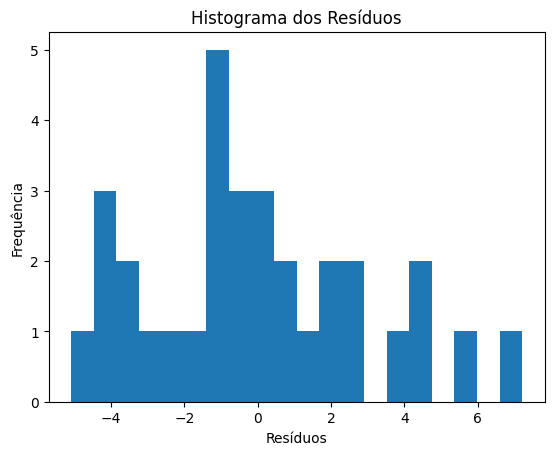

In [ ]:
residuos = modelo.resid
plt.hist(residuos, bins=20)
plt.xlabel('Resíduos')
plt.ylabel('Frequência')
plt.title('Histograma dos Resíduos')

#sns.displot(residuos, kde=True)

```markdown
### Passo 8: Gráfico de Probabilidade Normal (Q-Q Plot)

**O que este passo faz:** Plota um gráfico Q-Q (*Quantile-Quantile Plot*) comparando os quantis dos resíduos do nosso modelo com os quantis teóricos de uma distribuição normal perfeita (representada pela linha vermelha).

**Por que ele é necessário:** Nem sempre o histograma nos dá total certeza sobre a normalidade. O Q-Q plot facilita essa visualização.

**Como interpretar o resultado:**
Se os pontos azuis (nossos resíduos) estiverem bem alinhados sobre a linha reta vermelha, significa que nossos resíduos seguem uma distribuição normal. Desvios acentuados nas extremidades (curvas para longe da linha) sugerem desvios da normalidade.
```

Text(0.5, 1.0, 'Gráfico de plot de residuos')

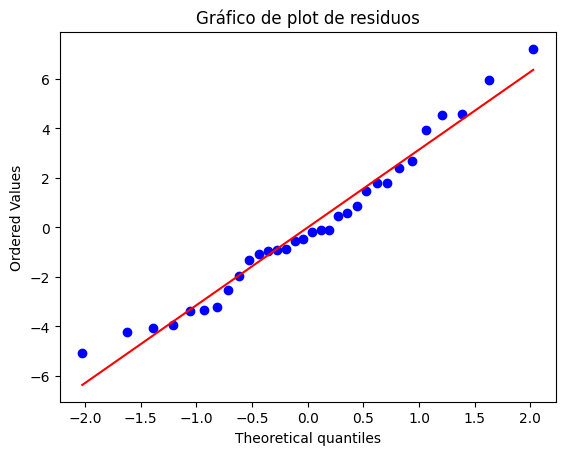

In [ ]:
# dificil analisar modelos pelos residuos
stats.probplot(residuos, dist="norm", plot=plt)
plt.title('Gráfico de plot de residuos')

```markdown
### Passo 9: Teste Estatístico de Normalidade (Shapiro-Wilk)

**O que este passo faz:** Executa o teste estatístico formal de Shapiro-Wilk sobre os resíduos do modelo.

**Por que ele é necessário:** Análises visuais de gráficos podem ser subjetivas. O teste estatístico nos fornece um veredito matemático objetivo baseado em probabilidade (p-valor).

**Como interpretar o resultado:**
*   **Hipótese Nula ($H_0$):** Os dados estão normalmente distribuídos.
*   **Se p-value $\le$ 0.05:** Rejeitamos a hipótese nula. Logo, os resíduos **não** seguem uma distribuição normal.
*   **Se p-value $>$ 0.05:** Não rejeitamos a hipótese nula. Aceitamos que os resíduos seguem uma distribuição normal.

**Veredito do nosso modelo:**
O p-value obtido foi **0.033** (menor que 0.05). Portanto, **rejeitamos a hipótese de normalidade**. Isso significa que as premissas para este modelo específico (`mpg ~ drat + cyl`) não foram totalmente atendidas, e precisamos de cautela ao interpretar seus testes de significância.
```

In [ ]:
# h0 - dados estão normalmente distribuidos
# p <= 0.05 é rejeitado a hipotese nula, então não estão distribuidos
# p > 0.05 não é possivel rejeitar a h0
stat, pval = stats.shapiro(residuos)
print(f'Shapiro-Wilk statistica: {stat:.3f}, p-value: {pval:.3f}')

Shapiro-Wilk statistica: 0.927, p-value: 0.033


```markdown
---

## ⚠️ Erros Comuns e Dicas Práticas

1.  **Ignorar os avisos do Teste de Resíduos:** Construir um modelo com ótimo $R^2$ mas cujos resíduos não são normais pode invalidar as margens de erro e testes de significância (p-values).
2.  **Não desempacotar variáveis no loop de plotagem:** Como vimos no Passo 5, ao fazer subplots automáticos, garanta que está iterando e atualizando corretamente tanto a variável $X$ quanto a $Y$ para não gerar múltiplos gráficos iguais.
3.  **Multicolinearidade:** Colocar variáveis altamente correlacionadas entre si (como `cyl` e `disp`) no mesmo modelo de regressão pode inflar a variância dos coeficientes e torná-los instáveis.

---

## 📝 Resumo da Aprendizagem

*   **Correlação não é Causalidade:** Identificamos que variáveis como peso (`wt`) e cilindros (`cyl`) estão fortemente associadas à eficiência do combustível.
*   **Construção de Modelos:** Aprendemos a usar fórmulas estatísticas com a biblioteca `statsmodels`.
*   **Validação de Hipóteses:** Vimos a importância de olhar além das métricas de acerto (como $R^2$) e avaliar graficamente e estatisticamente o comportamento dos resíduos para garantir a robustez científica do modelo.

---

## 🧠 Exercícios Propostos (Pratique!)

1.  **Exercício 1 (Fácil):** Altere a célula de dispersão (Passo 5) corrigindo o erro do loop de desempacotamento para exibir de forma correta cada um dos 6 gráficos propostos na lista `column_pairs`.
2.  **Exercício 2 (Médio):** Crie e treine um novo modelo estatístico utilizando a fórmula comentada no código: `mpg ~ disp + hp + wt`. Extraia seu sumário OLS e compare os valores de $R^2$, AIC e BIC com o modelo anterior. Ele foi melhor?
3.  **Exercício 3 (Desafiador):** Realize o teste de Shapiro-Wilk para os resíduos deste novo modelo (`mpg ~ disp + hp + wt`). Verifique se os erros deste novo modelo passam no teste de normalidade (p-value > 0.05).

---

## 🚀 Para ir além
Se você quiser se aprofundar ainda mais na área de regressão e modelagem estatística, pesquise sobre os seguintes termos:
*   **Homocedasticidade de Resíduos:** A premissa de que a variância dos erros deve ser constante.
*   **Multicolinearidade e VIF (Variance Inflation Factor):** Como identificar preditores que estão "atrapalhando" uns aos outros no modelo.
*   **Regularização (Lasso e Ridge):** Técnicas aplicadas para evitar sobreajuste em modelos lineares quando temos muitas variáveis preditoras.
```